# Long-Only Factor Trend Basket - Brazil

An individual investor in Brazil cannot short stocks without a lending account, so the easiest way to use factors is to buy only their long side. This notebook applies the trend index of `05_multi_factor_strategy` to the long leg of each of the 32 factors of `04_factor_screening`. Every month it chooses the factors with the best trend and buys all their stocks in a single basket. A stock chosen by more than one factor gets a larger weight.

The study has two stages:
- **Stage 1** uses the daily returns of each factor's long leg and keeps the factor weights fixed during the month. It is an approximation, used to compare the allocation rules quickly.
- **Stage 2** is the backtest of the single basket, stock by stock, with the engine of the other notebooks. It is also used to measure the concentration of the basket.

The long leg has two definitions: the 10 stocks with the highest signal (as in `05_`) and the top quintile (as in `04_`). Each test is run with the 32 factors and without the five composites. The results are in sample and before transaction costs.

In [1]:
# Library imports

import pandas as pd
import numpy as np
import statsmodels.api as sm
import quantstats as qs
from scipy import stats

import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import matplotlib.dates as mdates

from datetime import date, timedelta
from  bizdays import Calendar, set_option

cal = Calendar.load('ANBIMA')
set_option('mode', 'pandas')
from tqdm import tqdm

### Data and signals

The data, the universe and the z-scores are the same as in `04_factor_screening`; the cells below are copied from it without changes.

In [2]:
# Imports data already collected to make the analysis easier

path = '.'
factors_folder = 'factors'
data_folder = 'data'

companies = pd.read_csv(path + "/" + data_folder + "/" + 'index_composition.csv.gz', index_col = 'Date', date_format='%Y-%m-%d')
prices_df = pd.read_csv(path + "/" + data_folder + "/" + 'prices.csv.gz', index_col = 'Date', date_format='%Y-%m-%d')
volume = pd.read_csv(path + "/" + data_folder + "/" + 'volume.csv.gz', index_col = 'Date', date_format='%Y-%m-%d')
benchmarks = pd.read_csv(path + "/" + data_folder + "/" + 'benchmarks.csv.gz', index_col = 'Date', date_format='%Y-%m-%d')
ff_factors = pd.read_csv(path + "/" + data_folder + "/" + 'ff_factors.csv.gz', index_col = 'Date', date_format='%Y-%m-%d')

# Market factors
market_value = pd.read_csv(path + "/" + data_folder + "/" + 'relative_market_value.csv.gz', index_col = 'Date', date_format='%Y-%m-%d')
momentum = pd.read_csv(path + "/" + factors_folder + "/" + 'momentum.csv.gz', index_col = 'Date', date_format='%Y-%m-%d')
reversal = pd.read_csv(path + "/" + factors_folder + "/" + 'reversal.csv.gz', index_col = 'Date', date_format='%Y-%m-%d')
volatility = pd.read_csv(path + "/" + factors_folder + "/" + 'volatility.csv.gz', index_col = 'Date', date_format='%Y-%m-%d')
bab = pd.read_csv(path + "/" + factors_folder + "/" + 'bab.csv.gz', index_col = 'Date', date_format='%Y-%m-%d')
ivol = pd.read_csv(path + "/" + factors_folder + "/" + 'ivol.csv.gz', index_col = 'Date', date_format='%Y-%m-%d')

# Profitability factors
roe = pd.read_csv(path + "/" + factors_folder + "/" + 'roe.csv.gz', index_col = 'Date', date_format='%Y-%m-%d')
roa = pd.read_csv(path + "/" + factors_folder + "/" + 'roa.csv.gz', index_col = 'Date', date_format='%Y-%m-%d')
gpoa = pd.read_csv(path + "/" + factors_folder + "/" + 'gpoa.csv.gz', index_col = 'Date', date_format='%Y-%m-%d')
cfoa = pd.read_csv(path + "/" + factors_folder + "/" + 'cfoa.csv.gz', index_col = 'Date', date_format='%Y-%m-%d')
acc = pd.read_csv(path + "/" + factors_folder + "/" + 'acc.csv.gz', index_col = 'Date', date_format='%Y-%m-%d')

# Growth factors
g_revenue = pd.read_csv(path + "/" + factors_folder + "/" + 'g_revenue.csv.gz', index_col = 'Date', date_format='%Y-%m-%d')
g_ebitda = pd.read_csv(path + "/" + factors_folder + "/" + 'g_ebitda.csv.gz', index_col = 'Date', date_format='%Y-%m-%d')
g_earnings = pd.read_csv(path + "/" + factors_folder + "/" + 'g_earnings.csv.gz', index_col = 'Date', date_format='%Y-%m-%d')
investments = pd.read_csv(path + "/" + factors_folder + "/" + 'investments.csv.gz', index_col = 'Date', date_format='%Y-%m-%d')

# Leverage factors
debt_to_assets = pd.read_csv(path + "/" + factors_folder + "/" + 'debt_to_assets.csv.gz', index_col = 'Date', date_format='%Y-%m-%d')
debt_to_ebitda = pd.read_csv(path + "/" + factors_folder + "/" + 'debt_to_ebitda.csv.gz', index_col = 'Date', date_format='%Y-%m-%d')
debt_to_equity = pd.read_csv(path + "/" + factors_folder + "/" + 'debt_to_equity.csv.gz', index_col = 'Date', date_format='%Y-%m-%d')
liab_to_equity = pd.read_csv(path + "/" + factors_folder + "/" + 'liab_to_equity.csv.gz', index_col = 'Date', date_format='%Y-%m-%d')

# Value factors
earnings_yield = pd.read_csv(path + "/" + factors_folder + "/" + 'earnings_yield.csv.gz', index_col = 'Date', date_format='%Y-%m-%d')
book_to_price = pd.read_csv(path + "/" + factors_folder + "/" + 'book_to_price.csv.gz', index_col = 'Date', date_format='%Y-%m-%d')
sales_to_price = pd.read_csv(path + "/" + factors_folder + "/" + 'sales_to_price.csv.gz', index_col = 'Date', date_format='%Y-%m-%d')
fcf_to_price = pd.read_csv(path + "/" + factors_folder + "/" + 'fcf_to_price.csv.gz', index_col = 'Date', date_format='%Y-%m-%d')
ebitda_ev = pd.read_csv(path + "/" + factors_folder + "/" + 'ebitda_ev.csv.gz', index_col = 'Date', date_format='%Y-%m-%d')

# Magic Formula
roc_mf = pd.read_csv(path + "/" + factors_folder + "/" + 'roc_mf.csv.gz', index_col = 'Date', date_format='%Y-%m-%d')
earnings_yield_mf = pd.read_csv(path + "/" + factors_folder + "/" + 'earnings_yield_mf.csv.gz', index_col = 'Date', date_format='%Y-%m-%d')
debt_ebit_mf = pd.read_csv(path + "/" + factors_folder + "/" + 'debt_ebit_mf.csv.gz', index_col = 'Date', date_format='%Y-%m-%d')

# Index rebalancing dates
rebalance_dates = sorted(companies.index.unique())

# Backtest dates
ini_date = cal.preceding(rebalance_dates[0] - timedelta(days = 1)).date()
end_date = date.today()
nefin = pd.read_csv(path + "/" + data_folder + "/" + 'nefin_factors.csv.gz', index_col = 'Date', date_format='%Y-%m-%d')

In [3]:
ticker_codes = [tick[0:4] for tick in sorted(companies['Ticker'].unique())]
repeated_tickers = [tick for tick in ticker_codes if ticker_codes.count(tick) > 1]
repeated_tickers = list(dict.fromkeys(repeated_tickers))

vol_median = volume.ffill(limit=1).rolling(42).median()

for tick in repeated_tickers:
    rep = volume.columns[volume.columns.str.contains(tick)]
    ticker_filter = vol_median[rep].apply(lambda r: np.where(r == r.max(), r, np.nan), axis = 1)
    vol_median[rep] = pd.DataFrame(ticker_filter.tolist(), columns = rep, index = vol_median.index)

In [4]:
# Creates a matrix with the investable companies on each rebalancing date, showing the new index composition
investable = companies.loc[companies['Index'].isin(['SMLL', 'MLCX'])].pivot_table(index = 'Date', columns = 'Ticker', values = 'Weight')

# Multiplies by 0 and adds 1 to turn all values into 1, indicating that the company is investable
investable = investable.mul(0).add(1)

# Reindexes the table so that all backtest dates are present
investable = investable.reindex(market_value.index, method='ffill')
investable.loc[:date(2009,1,2)] = investable.loc[date(2009,1,5):date(2009,1,5)].values

# Creates a dataframe showing whether the stock had a price on the day, avoiding companies that left the market
has_price = prices_df.apply(lambda col: np.where((col.isna()) | (col <= 0), np.nan, 1)).loc[investable.index]

# Creates a dataframe to filter companies with low liquidity, avoiding companies whose prices are a problem to trade
volume_filter = vol_median.apply(lambda col: np.where(col > 1000, 1, np.nan))

In [5]:
# Sector filter for the Magic Formula
# Excludes Financials and Utilities companies
mf_filter = companies.loc[~companies['Sector'].isin(['Financeiro', 'Financeiro e Outros', 'Utilidade Pública'])].pivot_table(index = 'Date', columns = 'Ticker', values = 'Weight')

# Multiplies by 0 and adds 1 to turn all values into 1, indicating that the company is investable
mf_filter = mf_filter.mul(0).add(1)

# Reindexes the table so that all backtest dates are present
mf_filter = mf_filter.reindex(market_value.index, method='ffill')
mf_filter.loc[:date(2009,1,2)] = mf_filter.loc[date(2009,1,5):date(2009,1,5)].values

In [6]:
# Multiplies the indicators dataframe by investable and has_price to filter all dates at once
# Values multiplied by NaN become NaN, leaving only the values of companies that are investable on the date and have a price
roe = roe * investable * has_price * volume_filter
roa = roa * investable * has_price * volume_filter
gpoa = gpoa * investable * has_price * volume_filter
cfoa = cfoa * investable * has_price * volume_filter
acc = acc * investable * has_price * volume_filter

g_revenue = g_revenue * investable * has_price * volume_filter
g_ebitda = g_ebitda * investable * has_price * volume_filter
g_earnings = g_earnings * investable * has_price * volume_filter
investments = investments * investable * has_price * volume_filter

debt_to_assets = debt_to_assets * investable * has_price * volume_filter
debt_to_ebitda = debt_to_ebitda * investable * has_price * volume_filter
debt_to_equity = debt_to_equity * investable * has_price * volume_filter
liab_to_equity = liab_to_equity * investable * has_price * volume_filter

earnings_yield = earnings_yield * investable * has_price * volume_filter
book_to_price = book_to_price * investable * has_price * volume_filter
sales_to_price = sales_to_price * investable * has_price * volume_filter
fcf_to_price = fcf_to_price * investable * has_price * volume_filter
ebitda_ev = ebitda_ev * investable * has_price * volume_filter

momentum = momentum * investable * has_price * volume_filter
reversal = reversal * investable * has_price * volume_filter
volatility = volatility * investable * has_price * volume_filter
market_value = market_value * investable * has_price * volume_filter
bab = bab * investable * has_price * volume_filter
ivol = ivol * investable * has_price * volume_filter

roc_mf = roc_mf * investable * has_price * volume_filter * mf_filter
earnings_yield_mf = earnings_yield_mf * investable * has_price * volume_filter * mf_filter
debt_ebit_mf = debt_ebit_mf * investable * has_price * volume_filter * mf_filter

# Reindexes the dataframes so that all backtest dates are present
roe = roe.loc[volume.index]
roa = roa.loc[volume.index]
gpoa = gpoa.loc[volume.index]
cfoa = cfoa.loc[volume.index]
acc = acc.loc[volume.index]

g_revenue = g_revenue.loc[volume.index]
g_ebitda = g_ebitda.loc[volume.index]
g_earnings = g_earnings.loc[volume.index]
investments = investments.loc[volume.index]

debt_to_assets = debt_to_assets.loc[volume.index]
debt_to_ebitda = debt_to_ebitda.loc[volume.index]
debt_to_equity = debt_to_equity.loc[volume.index]
liab_to_equity = liab_to_equity.loc[volume.index]

earnings_yield = earnings_yield.loc[volume.index]
book_to_price = book_to_price.loc[volume.index]
sales_to_price = sales_to_price.loc[volume.index]
fcf_to_price = fcf_to_price.loc[volume.index]
ebitda_ev = ebitda_ev.loc[volume.index]

momentum = momentum.loc[volume.index]
reversal = reversal.loc[volume.index]
volatility = volatility.loc[volume.index]
market_value = market_value.loc[volume.index]
bab = bab.loc[volume.index]
ivol = ivol.loc[volume.index]

roc_mf = roc_mf.loc[volume.index]
earnings_yield_mf = earnings_yield_mf.loc[volume.index]
debt_ebit_mf = debt_ebit_mf.loc[volume.index]

In [7]:
# Calculates z-scores using numpy
z_roe = stats.zscore(roe.values, axis=1, nan_policy='omit')
z_roa = stats.zscore(roa.values, axis=1, nan_policy='omit')
z_gpoa = stats.zscore(gpoa.values, axis=1, nan_policy='omit')
z_cfoa = stats.zscore(cfoa.values, axis=1, nan_policy='omit')
z_acc = stats.zscore(acc.values, axis=1, nan_policy='omit')
z_g_revenue = stats.zscore(g_revenue.values, axis=1, nan_policy='omit')
z_g_ebitda = stats.zscore(g_ebitda.values, axis=1, nan_policy='omit')
z_g_earnings = stats.zscore(g_earnings.values, axis=1, nan_policy='omit')
z_investments = stats.zscore(investments.values, axis=1, nan_policy='omit')
z_debt_to_assets = stats.zscore(debt_to_assets.values, axis=1, nan_policy='omit')
z_debt_to_ebitda = stats.zscore(debt_to_ebitda.values, axis=1, nan_policy='omit')
z_debt_to_equity = stats.zscore(debt_to_equity.values, axis=1, nan_policy='omit')
z_liab_to_equity = stats.zscore(liab_to_equity.values, axis=1, nan_policy='omit')
z_ey = stats.zscore(earnings_yield.values, axis=1, nan_policy='omit')
z_bp = stats.zscore(book_to_price.values, axis=1, nan_policy='omit')
z_sales = stats.zscore(sales_to_price.values, axis=1, nan_policy='omit')
z_fcf = stats.zscore(fcf_to_price.values, axis=1, nan_policy='omit')
z_ev = stats.zscore(ebitda_ev.values, axis=1, nan_policy='omit')
z_mom = stats.zscore(momentum.values, axis=1, nan_policy='omit')
z_rev = stats.zscore(reversal.values, axis=1, nan_policy='omit')
z_vol = stats.zscore(volatility.values, axis=1, nan_policy='omit')
z_size = stats.zscore(market_value.values, axis=1, nan_policy='omit')
z_bab = stats.zscore(bab.values, axis=1, nan_policy='omit')
z_ivol = stats.zscore(ivol.values, axis=1, nan_policy='omit')
z_roc_mf = stats.zscore(roc_mf.values, axis=1, nan_policy='omit')
z_ey_mf = stats.zscore(earnings_yield_mf.values, axis=1, nan_policy='omit')
z_de_mf = stats.zscore(debt_ebit_mf.values, axis=1, nan_policy='omit')

# Replaces values outside the [-2, 2] range with NaN
z_roe = np.where((z_roe >= -2) & (z_roe <= 2), z_roe, np.nan)
z_roa = np.where((z_roa >= -2) & (z_roa <= 2), z_roa, np.nan)
z_gpoa = np.where((z_gpoa >= -2) & (z_gpoa <= 2), z_gpoa, np.nan)
z_cfoa = np.where((z_cfoa >= -2) & (z_cfoa <= 2), z_cfoa, np.nan)
z_acc = np.where((z_acc >= -2) & (z_acc <= 2), z_acc, np.nan)
z_g_revenue = np.where((z_g_revenue >= -2) & (z_g_revenue <= 2), z_g_revenue, np.nan)
z_g_ebitda = np.where((z_g_ebitda >= -2) & (z_g_ebitda <= 2), z_g_ebitda, np.nan)
z_g_earnings = np.where((z_g_earnings >= -2) & (z_g_earnings <= 2), z_g_earnings, np.nan)
z_investments = np.where((z_investments >= -2) & (z_investments <= 2), z_investments, np.nan)
z_debt_to_assets = np.where((z_debt_to_assets >= -2) & (z_debt_to_assets <= 2), z_debt_to_assets, np.nan)
z_debt_to_ebitda = np.where((z_debt_to_ebitda >= -2) & (z_debt_to_ebitda <= 2), z_debt_to_ebitda, np.nan)
z_debt_to_equity = np.where((z_debt_to_equity >= -2) & (z_debt_to_equity <= 2), z_debt_to_equity, np.nan)
z_liab_to_equity = np.where((z_liab_to_equity >= -2) & (z_liab_to_equity <= 2), z_liab_to_equity, np.nan)
z_ey = np.where((z_ey >= -2) & (z_ey <= 2), z_ey, np.nan)
z_bp = np.where((z_bp >= -2) & (z_bp <= 2), z_bp, np.nan)
z_sales = np.where((z_sales >= -2) & (z_sales <= 2), z_sales, np.nan)
z_fcf = np.where((z_fcf >= -2) & (z_fcf <= 2), z_fcf, np.nan)
z_ev = np.where((z_ev >= -2) & (z_ev <= 2), z_ev, np.nan)
z_roc_mf = np.where((z_roc_mf >= -2) & (z_roc_mf <= 2), z_roc_mf, np.nan)
z_ey_mf = np.where((z_ey_mf >= -2) & (z_ey_mf <= 2), z_ey_mf, np.nan)
z_de_mf = np.where((z_de_mf >= -2) & (z_de_mf <= 2), z_de_mf, np.nan)

# Converts the result back to a DataFrame, preserving index and columns
z_roe = pd.DataFrame(z_roe, columns=roe.columns, index=roe.index)
z_roa = pd.DataFrame(z_roa, columns=roa.columns, index=roa.index)
z_gpoa = pd.DataFrame(z_gpoa, columns=gpoa.columns, index=gpoa.index)
z_cfoa = pd.DataFrame(z_cfoa, columns=cfoa.columns, index=cfoa.index)
z_acc = pd.DataFrame(z_acc, columns=acc.columns, index=acc.index)
z_g_revenue = pd.DataFrame(z_g_revenue, columns=g_revenue.columns, index=g_revenue.index)
z_g_ebitda = pd.DataFrame(z_g_ebitda, columns=g_ebitda.columns, index=g_ebitda.index)
z_g_earnings = pd.DataFrame(z_g_earnings, columns=g_earnings.columns, index=g_earnings.index)
z_investments = pd.DataFrame(z_investments, columns=investments.columns, index=investments.index)
z_debt_to_assets = pd.DataFrame(z_debt_to_assets, columns=debt_to_assets.columns, index=debt_to_assets.index)
z_debt_to_ebitda = pd.DataFrame(z_debt_to_ebitda, columns=debt_to_ebitda.columns, index=debt_to_ebitda.index)
z_debt_to_equity = pd.DataFrame(z_debt_to_equity, columns=debt_to_equity.columns, index=debt_to_equity.index)
z_liab_to_equity = pd.DataFrame(z_liab_to_equity, columns=liab_to_equity.columns, index=liab_to_equity.index)
z_ey = pd.DataFrame(z_ey, columns=earnings_yield.columns, index=earnings_yield.index)
z_bp = pd.DataFrame(z_bp, columns=book_to_price.columns, index=book_to_price.index)
z_sales = pd.DataFrame(z_sales, columns=sales_to_price.columns, index=sales_to_price.index)
z_fcf = pd.DataFrame(z_fcf, columns=fcf_to_price.columns, index=fcf_to_price.index)
z_ev = pd.DataFrame(z_ev, columns=ebitda_ev.columns, index=ebitda_ev.index)
z_mom = pd.DataFrame(z_mom, columns=momentum.columns, index=momentum.index)
z_rev = pd.DataFrame(z_rev, columns=reversal.columns, index=reversal.index)
z_vol = pd.DataFrame(z_vol, columns=volatility.columns, index=volatility.index)
z_size = pd.DataFrame(z_size, columns=market_value.columns, index=market_value.index)
z_bab = pd.DataFrame(z_bab, columns=bab.columns, index=bab.index)
z_ivol = pd.DataFrame(z_ivol, columns=ivol.columns, index=ivol.index)
z_roc_mf = pd.DataFrame(z_roc_mf, columns=roc_mf.columns, index=roc_mf.index)
z_ey_mf = pd.DataFrame(z_ey_mf, columns=earnings_yield_mf.columns, index=earnings_yield_mf.index)
z_de_mf = pd.DataFrame(z_de_mf, columns=debt_ebit_mf.columns, index=debt_ebit_mf.index)

# Calculates the aggregate scores
z_profitability = z_roe + z_gpoa + z_cfoa + z_acc + z_roa
z_growth = z_g_revenue + z_g_ebitda + z_g_earnings
z_safety = -z_debt_to_assets - z_debt_to_ebitda - z_liab_to_equity
z_value = z_ev + z_ey + z_fcf + z_bp + z_sales
z_mf = -stats.zscore(roc_mf.rank(axis=1, ascending=False) + earnings_yield_mf.rank(axis=1, ascending=False) + debt_ebit_mf.rank(axis=1, ascending=True), axis=1, nan_policy='omit')

# Converts the final result to a DataFrame
z_mf = pd.DataFrame(z_mf, columns=roc_mf.columns, index=roc_mf.index)

In [8]:
from brfactors.selection import get_quintiles, get_longshort_decile, get_longshort_amount
from brfactors.backtest import backtest_quintiles, backtest_longshort
from brfactors.trend import trend_signal

In [9]:
# Value Factors
value = {'Book to Price' : z_bp, 'EV to Ebitda' : z_ev, 'Sales to Price' : z_sales, 'Free Cash Flow to Price' : z_fcf, 'Earnings Yield' : z_ey, 'Value Composite' : z_value}
profitability = {'Return on Equity' : z_roe, 'Return on Assets' : z_roa, 'Gross Profit over Assets' : z_gpoa, 'Cashflow over Assets' : z_cfoa, 'Accruals' : z_acc, 'Profitability Composite' : z_profitability}
growth = {'Revenue Growth' : z_g_revenue, 'Ebitda Growth' : z_g_ebitda, 'Earnings Growth' : z_g_earnings, 'Growth Composite' : z_growth, "Investments": z_investments}
leverage = {'Debt to Assets' : -z_debt_to_assets, 'Debt to Ebitda' : -z_debt_to_ebitda, 'Debt to Equity' : -z_debt_to_equity, 'Liabilities to Equity' : -z_liab_to_equity, 'Leverage Composite' : z_safety}
market = {'Momentum' : z_mom, 'Reversal' : z_rev, 'Low Vol' : -z_vol, 'Size' : -z_size, 'BAB' : z_bab, 'IVOL' : -z_ivol}
magic_formula = {'Return on Capital' : z_roc_mf, 'Earnings Yield MF' : z_ey_mf, 'Debt to Ebit MF' : -z_de_mf, 'Magic Formula Composite' : z_mf}

# List with all factors
factors_dict = dict()
factors_dict.update(value)
factors_dict.update(profitability)
factors_dict.update(growth)
factors_dict.update(leverage)
factors_dict.update(market)
factors_dict.update(magic_formula)

# Family of each factor and the five composites
families = {'Value': value, 'Profitability': profitability, 'Growth': growth, 'Leverage': leverage, 'Market': market, 'Magic Formula': magic_formula}
family_of = {factor: family for family, factors in families.items() for factor in factors}
composites = ['Value Composite', 'Profitability Composite', 'Growth Composite', 'Leverage Composite', 'Magic Formula Composite']
factor_sets = {'All 32': list(factors_dict.keys()), 'No composites': [f for f in factors_dict.keys() if f not in composites]}

# Long legs of the factors

For each factor, the long leg is rebalanced on the first business day of each month with equal weights, as in `04_`. Two definitions are used:
- **Top10**: the 10 stocks with the highest signal;
- **5Q**: the top quintile of the signal.

In [10]:
# Creates a list with all rebalancing dates
rebalance_dates = [date(year, month, 1) for year in range(2009, 2027) for month in range(1,13, 1)]

# Checks whether the date is a business day, if not, returns the next business day
rebalance_dates = [cal.following(ref_date) for ref_date in rebalance_dates if ref_date <= prices_df.index[-1].date()]

leg_types = ['Top10', '5Q']
legs = {leg: dict() for leg in leg_types}
leg_returns = {leg: dict() for leg in leg_types}

for factor_name, factor_data in tqdm(factors_dict.items()):
    _, top10 = get_longshort_amount(10, factor_data)
    legs['Top10'][factor_name] = top10
    legs['5Q'][factor_name] = get_quintiles(0.8, 1.0, factor_data)

    for leg in leg_types:
        leg_returns[leg][factor_name] = backtest_quintiles(prices_df, legs[leg][factor_name], rebalance_dates, market_value)

# A leg earns zero before it holds its first stock; those days are set to NaN so that they do not enter the trend
leg_returns = {leg: pd.DataFrame(rets) for leg, rets in leg_returns.items()}
leg_returns = {leg: rets.where(rets.ne(0).cummax()) for leg, rets in leg_returns.items()}

  0%|          | 0/32 [00:00<?, ?it/s]

  3%|▎         | 1/32 [00:04<02:26,  4.73s/it]

  6%|▋         | 2/32 [00:09<02:19,  4.66s/it]

  9%|▉         | 3/32 [00:13<02:14,  4.65s/it]

 12%|█▎        | 4/32 [00:18<02:10,  4.65s/it]

 16%|█▌        | 5/32 [00:23<02:05,  4.64s/it]

... (24 outputs left out)

 94%|█████████▍| 30/32 [02:25<00:10,  5.13s/it]

 97%|█████████▋| 31/32 [02:30<00:05,  5.13s/it]

100%|██████████| 32/32 [02:35<00:00,  5.24s/it]

100%|██████████| 32/32 [02:35<00:00,  4.87s/it]

# Trend of the long legs

The trend indicator is the one of `05_`: four spreads between exponential moving averages of the cumulative return, each normalized by its standard deviation over 252 days and passed through the hyperbolic tangent, then averaged. It goes from -1 to 1. It is in `brfactors/trend.py`.

A factor can only be chosen once its indicator exists, about 252 days after its leg starts. The factors therefore enter the strategy over time.

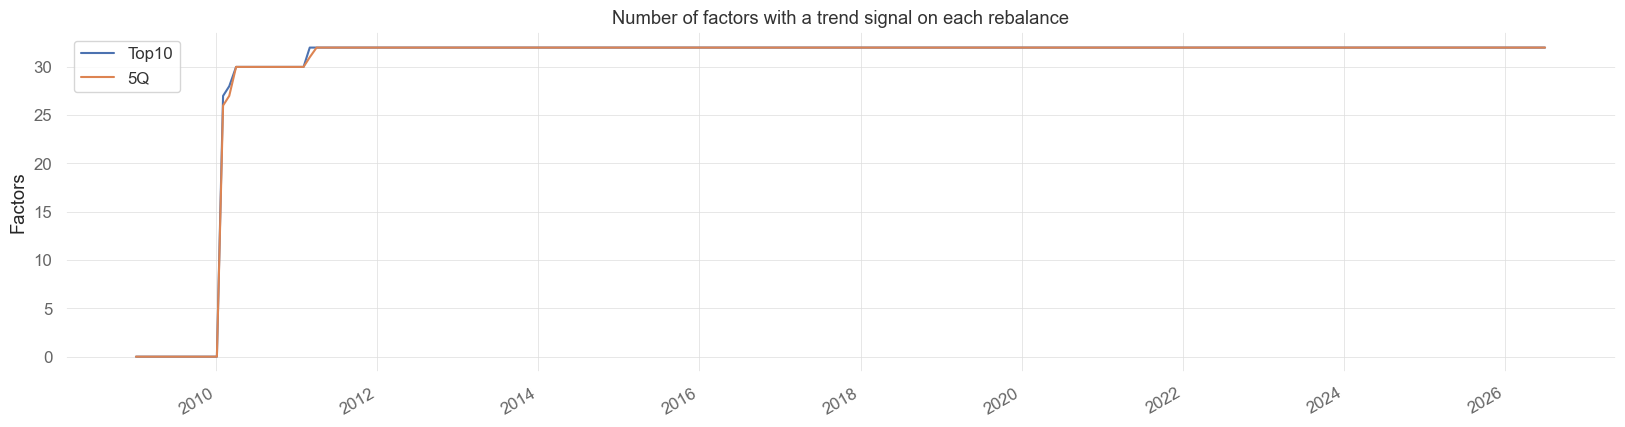

In [11]:
signals = {leg: trend_signal(leg_returns[leg]) for leg in leg_types}

# Dates of the signals: the day before each rebalance
trade_dates = [pd.Timestamp(dt) for dt in rebalance_dates if pd.Timestamp(dt) in prices_df.index]
signal_dates = [prices_df.index[prices_df.index.get_loc(dt) - 1] for dt in trade_dates]

eligible = pd.DataFrame({leg: signals[leg].loc[signal_dates].notna().sum(axis = 1).values for leg in leg_types}, index = trade_dates)
eligible.plot(figsize = (20,5), title = 'Number of factors with a trend signal on each rebalance')
plt.ylabel('Factors')
plt.grid(True)

Text(0.5, 1.0, 'Trend signal of the Top10 long legs on each rebalance')

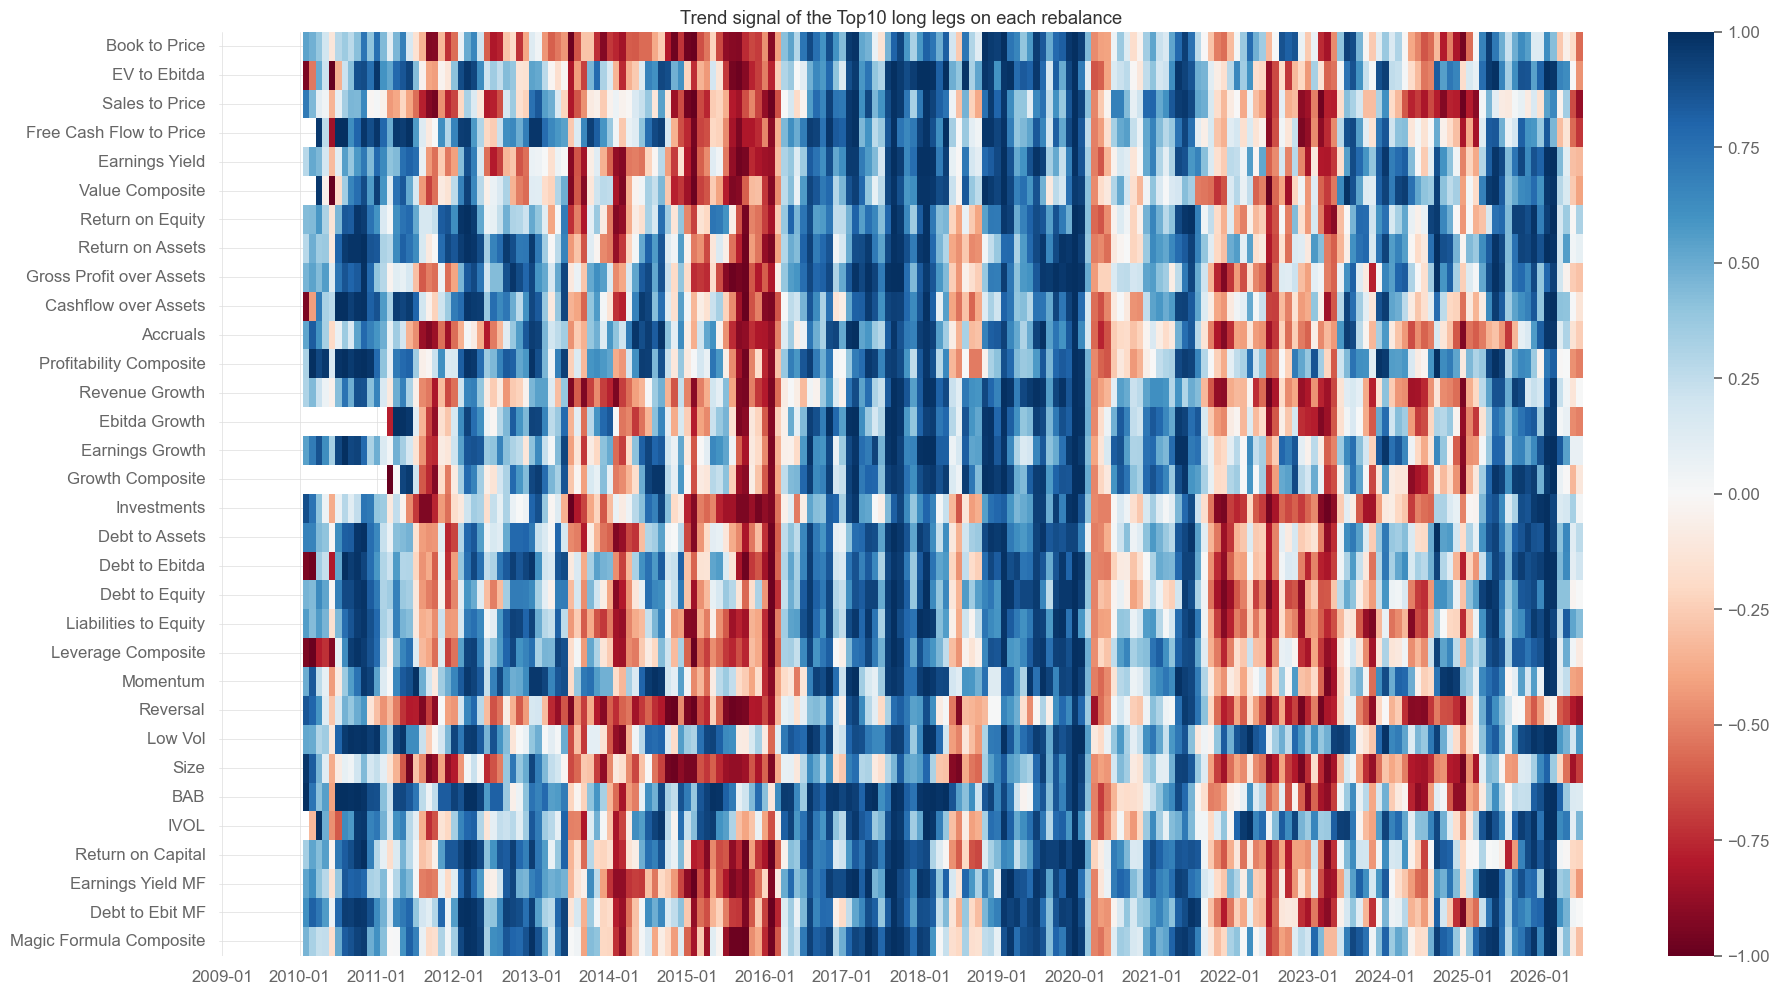

In [12]:
import seaborn as sns

monthly_signal = signals['Top10'].loc[signal_dates]
monthly_signal.index = [dt.strftime('%Y-%m') for dt in trade_dates]

plt.figure(figsize = (22,12))
sns.heatmap(monthly_signal.T, cmap = 'RdBu', center = 0, vmin = -1, vmax = 1, xticklabels = 12)
plt.title('Trend signal of the Top10 long legs on each rebalance')

# Allocation rules

On each rebalance, the rule uses the trend signal `s` of the eligible factors on the day before:
- **EQ10**: the 10 factors with the highest signal, with equal weights, fully invested;
- **EQ10+**: the same 10, but only those with a positive signal; the empty slots go to the CDI;
- **GR**: all factors, with weights proportional to `max(s, 0)`, normalized to 100%;
- **GR-CDI (s+1)/2**: the 10 best factors, each with a budget of `(s+1)/2 / 10`, the convention of `05_`; the rest goes to the CDI;
- **GR-CDI max(s,0)**: the same, with a budget of `max(s, 0) / 10`, so a factor with a negative trend gets nothing;
- **All equal**: the control, all eligible factors with equal weights and no trend.

While fewer than 10 factors are eligible, the rules divide by the number available.

In [13]:
def allocate(s, rule, n = 10):
    # Returns the weight of each factor, given the trend signals of the day before the rebalance
    s = s.dropna()
    w = pd.Series(0.0, index = s.index)
    if len(s) == 0:
        return w

    k = min(n, len(s))
    top = s.sort_values(ascending = False).index[:k]

    if rule == 'EQ10':
        w[top] = 1 / k
    elif rule == 'EQ10+':
        w[[f for f in top if s[f] > 0]] = 1 / k
    elif rule == 'GR':
        g = s.clip(lower = 0)
        if g.sum() > 0:
            w = g / g.sum()
    elif rule == 'GR-CDI (s+1)/2':
        w[top] = (s[top] + 1) / 2 / k
    elif rule == 'GR-CDI max(s,0)':
        w[top] = s[top].clip(lower = 0) / k
    elif rule == 'All equal':
        w[:] = 1 / len(s)

    return w

rules = ['EQ10', 'EQ10+', 'GR', 'GR-CDI (s+1)/2', 'GR-CDI max(s,0)', 'All equal']
variants = [(leg, fset, rule) for leg in leg_types for fset in factor_sets for rule in rules]

# Factor weights of each variant, indexed by the rebalancing date
factor_weights = dict()
for leg, fset, rule in variants:
    cols = factor_sets[fset]
    factor_weights[(leg, fset, rule)] = pd.DataFrame({dt: allocate(signals[leg].loc[dtm1, cols], rule) for dt, dtm1 in zip(trade_dates, signal_dates)}).T.reindex(columns = cols).fillna(0)

# The strategy starts on the first rebalance with an eligible factor
first_rebalance = factor_weights[('Top10', 'All 32', 'EQ10')].sum(axis = 1).gt(0).idxmax()
start_date = prices_df.index[prices_df.index.get_loc(first_rebalance) + 1]
print(f'First rebalance: {first_rebalance.date()}, returns from {start_date.date()}')

First rebalance: 2010-02-01, returns from 2010-02-02


## Stage 1: factor return series

The portfolio return is `sum(w_f * r_f) + (1 - sum(w_f)) * CDI`, where `r_f` is the daily return of the long leg. The weights decided on the rebalance earn returns from the next day on and stay fixed until the next rebalance, so this is an approximation of the real portfolio.

In [14]:
cdi = benchmarks['CDI'].reindex(prices_df.index)
stage1_returns = dict()

for leg, fset, rule in variants:
    cols = factor_sets[fset]
    W = factor_weights[(leg, fset, rule)].reindex(prices_df.index).ffill().shift(1)
    port = (W * leg_returns[leg][cols].fillna(0)).sum(axis = 1) + (1 - W.sum(axis = 1)) * cdi
    stage1_returns[(leg, fset, rule)] = port.loc[start_date:]

## Stage 2: single basket

The weight of each stock is the sum, over the chosen factors, of the factor weight divided by the number of stocks in its leg: `W = sum(w_f * L_f / n_f)`. With Top10 legs and EQ10 this is the same as adding up the 0/1 matrices of the chosen factors. The part that is not invested goes to the CDI, which enters the price table as a pseudo-asset, so that `backtest_quintiles` handles its drift like any other position.

In [15]:
# Prices with the CDI as a pseudo-asset
prices_cdi = prices_df.copy()
prices_cdi['CDI'] = cdi.fillna(0).add(1).cumprod()

def stock_weights(leg, fset, rule):
    # Returns the stock weights of a variant on the day before each rebalance, which is the day the engine reads
    W = factor_weights[(leg, fset, rule)]
    weights = pd.DataFrame(0.0, index = signal_dates, columns = prices_cdi.columns)

    for dt, dtm1 in zip(trade_dates, signal_dates):
        for factor, wf in W.loc[dt].items():
            if wf <= 0:
                continue
            stocks = legs[leg][factor].loc[dtm1]
            stocks = stocks[stocks > 0]
            if len(stocks) > 0:
                weights.loc[dtm1, stocks.index] += wf / len(stocks)
        weights.loc[dtm1, 'CDI'] = max(0.0, 1 - weights.loc[dtm1].drop('CDI').sum())

    return weights

basket_weights = dict()
stage2_returns = dict()
for variant in tqdm(variants):
    basket_weights[variant] = stock_weights(*variant)
    stage2_returns[variant] = backtest_quintiles(prices_cdi, basket_weights[variant], rebalance_dates, market_value).loc[start_date:]

  0%|          | 0/24 [00:00<?, ?it/s]

  4%|▍         | 1/24 [00:04<01:36,  4.19s/it]

  8%|▊         | 2/24 [00:08<01:29,  4.09s/it]

 12%|█▎        | 3/24 [00:13<01:40,  4.81s/it]

 17%|█▋        | 4/24 [00:18<01:33,  4.66s/it]

 21%|██        | 5/24 [00:22<01:23,  4.40s/it]

... (16 outputs left out)

 92%|█████████▏| 22/24 [01:43<00:09,  4.72s/it]

 96%|█████████▌| 23/24 [01:47<00:04,  4.56s/it]

100%|██████████| 24/24 [01:54<00:00,  5.17s/it]

100%|██████████| 24/24 [01:54<00:00,  4.77s/it]

### Control: the Combination of `05_`

The Combination of `05_multi_factor_strategy`, rebuilt here over the same window. Its signals are those of `05_`, which differ from those of `04_`: momentum and volatility are trimmed at 2 standard deviations, the Profitability composite leaves out CFOA, the Value composite leaves out FCF to Price, and the Magic Formula ranking also uses volatility and momentum.

In [16]:
# Signals of 05_multi_factor_strategy
z_mom_05 = z_mom.where((z_mom >= -2) & (z_mom <= 2))
z_vol_05 = z_vol.where((z_vol >= -2) & (z_vol <= 2))
z_profitability_05 = z_roe + z_gpoa + z_acc + z_roa
z_value_05 = z_ev + z_ey + z_bp + z_sales
z_mf_05 = -stats.zscore(roc_mf.rank(axis=1, ascending=False) +
                        earnings_yield_mf.rank(axis=1, ascending=False) +
                        debt_ebit_mf.rank(axis=1, ascending=True) +
                        volatility.rank(axis = 1, ascending = True) +
                        momentum.rank(axis=1, ascending=False), axis=1, nan_policy='omit')
z_mf_05 = pd.DataFrame(z_mf_05, columns=roc_mf.columns, index=roc_mf.index)

# Stock selection and backtest, as in 05_
short_mf, long_mf = get_longshort_amount(10, z_mf_05) # Magic Formula
short_momvol, long_momvol = get_longshort_amount(10, -z_vol_05, use_filter = True, filter_signal = [z_mom_05], filter_percentile = [0.8]) # LowVol Momentum
short_quality, long_quality = get_longshort_amount(10, z_profitability_05 + z_value_05, use_filter = True, filter_signal = [z_safety, z_growth], filter_percentile = [0.2, 0.2]) # Quality
ret_comb = backtest_quintiles(prices_df, long_mf + long_momvol + long_quality, rebalance_dates, market_value)

print(f"Combination from January 2009, annualized return: {ret_comb.dropna().add(1).prod() ** (252 / len(ret_comb.dropna())) - 1:.1%}")

Combination from January 2009, annualized return: 17.1%


# Results

Statistics from the first month with a signal to the end of the sample. The Sharpe ratio is the mean excess return over the CDI divided by the volatility, as in the other notebooks. The alpha and the market beta come from a regression of the monthly excess returns on the NEFIN factors (market, SMB, HML and WML), as in `05_`.

In [17]:
def statistics(ret):
    ret = ret.dropna()
    excess = ret - cdi.loc[ret.index]
    return {'Annualized Return': ret.add(1).prod() ** (252 / len(ret)) - 1,
            'Volatility': ret.std() * np.sqrt(252),
            'Sharpe Ratio': excess.mean() * 252 / (ret.std() * np.sqrt(252)),
            'Max Drawdown': qs.stats.max_drawdown(ret)}

def nefin_regression(ret):
    returns_nefin = pd.merge(ret.rename('Daily return'), nefin[['Rm_minus_Rf', 'Risk_Free', 'SMB', 'HML', 'WML']], how = 'left', left_index = True, right_index = True).dropna()
    returns_nefin['Excess_Return'] = returns_nefin['Daily return'] - returns_nefin['Risk_Free']
    monthly = returns_nefin.resample('ME').apply(lambda x: (x + 1).prod() - 1)
    model = sm.OLS(monthly['Excess_Return'], sm.add_constant(monthly[['Rm_minus_Rf', 'SMB', 'HML', 'WML']])).fit()
    return {'Alpha (month)': model.params['const'], 'Alpha t-stat': model.tvalues['const'], 'Market beta': model.params['Rm_minus_Rf']}

first_signal_date = signal_dates[trade_dates.index(first_rebalance)]
results = dict()
for variant in variants:
    row = statistics(stage2_returns[variant])
    row['Stage 1 Return'] = statistics(stage1_returns[variant])['Annualized Return']
    row.update(nefin_regression(stage2_returns[variant]))
    row['Equity Exposure'] = 1 - basket_weights[variant].loc[first_signal_date:, 'CDI'].mean()
    results[' | '.join(variant)] = row

controls = {'05 Combination': ret_comb.loc[start_date:], 'IBOV': benchmarks['IBOV'].loc[start_date:], 'SMLL': benchmarks['SMLL'].loc[start_date:], 'CDI': benchmarks['CDI'].loc[start_date:]}
for name, ret in controls.items():
    row = statistics(ret)
    if name == '05 Combination':
        row.update(nefin_regression(ret))
    results[name] = row

results = pd.DataFrame(results).T
results_fmt = results.copy()
for col in ['Annualized Return', 'Stage 1 Return', 'Volatility', 'Max Drawdown', 'Equity Exposure']:
    results_fmt[col] = results_fmt[col].map(lambda x: '' if pd.isna(x) else f'{x:.1%}')
results_fmt['Alpha (month)'] = results_fmt['Alpha (month)'].map(lambda x: '' if pd.isna(x) else f'{x:.2%}')
for col in ['Sharpe Ratio', 'Alpha t-stat', 'Market beta']:
    results_fmt[col] = results_fmt[col].map(lambda x: '' if pd.isna(x) else f'{x:.2f}')
results_fmt[['Annualized Return', 'Stage 1 Return', 'Volatility', 'Sharpe Ratio', 'Max Drawdown', 'Alpha (month)', 'Alpha t-stat', 'Market beta', 'Equity Exposure']]

,Annualized Return,Stage 1 Return,Volatility,Sharpe Ratio,Max Drawdown,Alpha (month),Alpha t-stat,Market beta,Equity Exposure
Top10 | All 32 | EQ10,13.6%,13.5%,20.5%,0.27,-50.3%,0.45%,3.27,0.98,100.0%
Top10 | All 32 | EQ10+,8.2%,8.1%,18.6%,0.01,-51.6%,-0.02%,-0.13,0.86,87.9%
Top10 | All 32 | GR,8.4%,8.4%,19.5%,0.03,-50.9%,0.05%,0.31,0.91,98.5%
Top10 | All 32 | GR-CDI (s+1)/2,11.5%,11.4%,15.3%,0.17,-40.3%,0.19%,1.46,0.73,78.6%
"Top10 | All 32 | GR-CDI max(s,0)",10.9%,10.7%,12.0%,0.13,-30.3%,0.09%,0.57,0.51,60.5%
Top10 | All 32 | All equal,8.6%,8.5%,21.7%,0.06,-50.8%,0.19%,1.53,1.03,100.0%
Top10 | No composites | EQ10,13.7%,13.6%,20.6%,0.27,-51.6%,0.45%,3.45,0.99,100.0%
Top10 | No composites | EQ10+,8.2%,8.2%,18.3%,0.01,-52.4%,-0.05%,-0.25,0.85,85.6%
Top10 | No composites | GR,8.2%,8.1%,19.5%,0.02,-51.8%,0.02%,0.11,0.92,98.0%
Top10 | No composites | GR-CDI (s+1)/2,11.4%,11.2%,15.0%,0.17,-41.1%,0.16%,1.26,0.72,76.7%


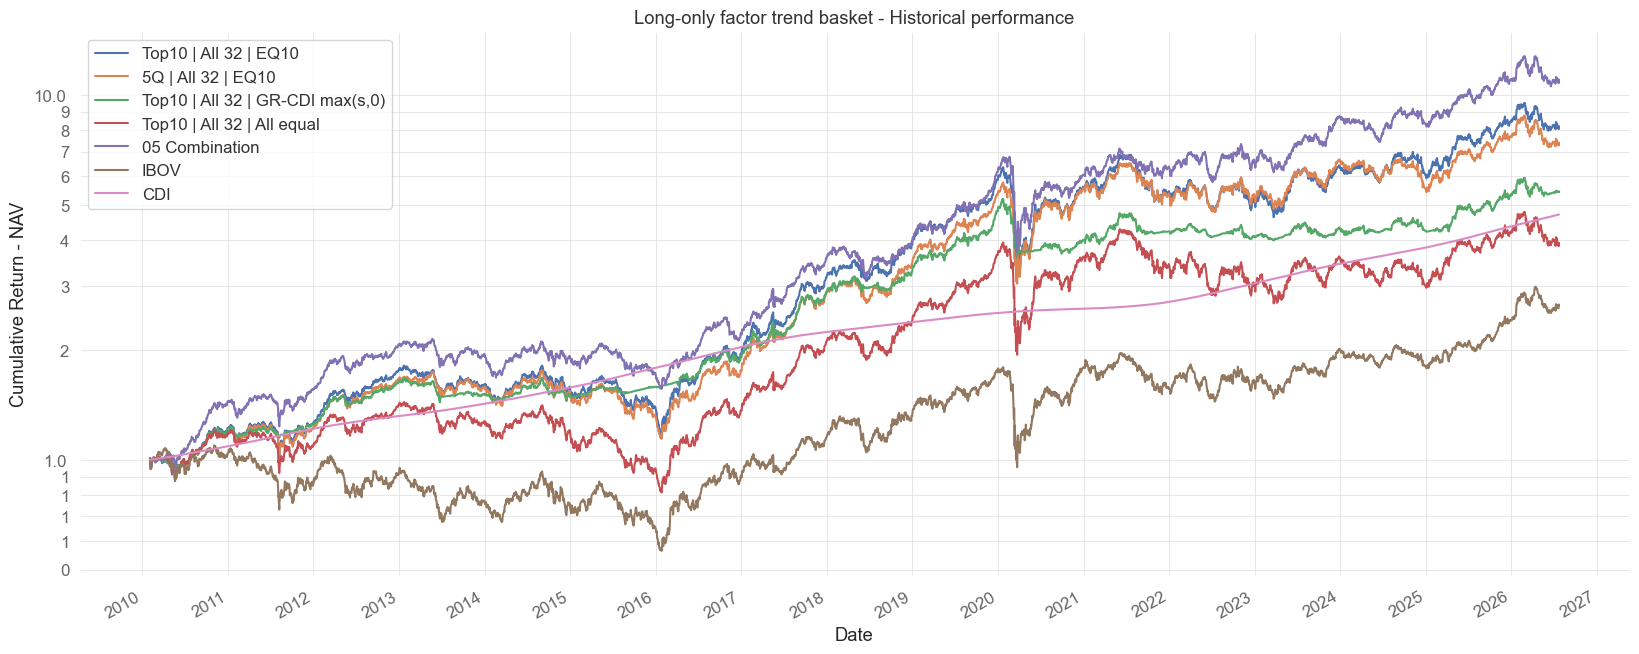

In [18]:
# Historical performance of the main variants
main_variants = [('Top10', 'All 32', 'EQ10'), ('5Q', 'All 32', 'EQ10'), ('Top10', 'All 32', 'GR-CDI max(s,0)'), ('Top10', 'All 32', 'All equal')]
for variant in main_variants:
    stage2_returns[variant].add(1).cumprod().plot(figsize = (20,8), label = ' | '.join(variant))
controls['05 Combination'].add(1).cumprod().plot(label = '05 Combination')
controls['IBOV'].add(1).cumprod().plot(label = 'IBOV')
controls['CDI'].add(1).cumprod().plot(label = 'CDI')

plt.title('Long-only factor trend basket - Historical performance')
plt.legend()
plt.ylabel('Cumulative Return - NAV')
plt.xlabel('Date')
plt.yscale('log')
plt.gca().yaxis.set_major_formatter(ticker.ScalarFormatter())
plt.gca().yaxis.set_minor_formatter(ticker.ScalarFormatter())
plt.gca().xaxis.set_major_locator(mdates.YearLocator(1))
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
plt.grid(True, which='both')

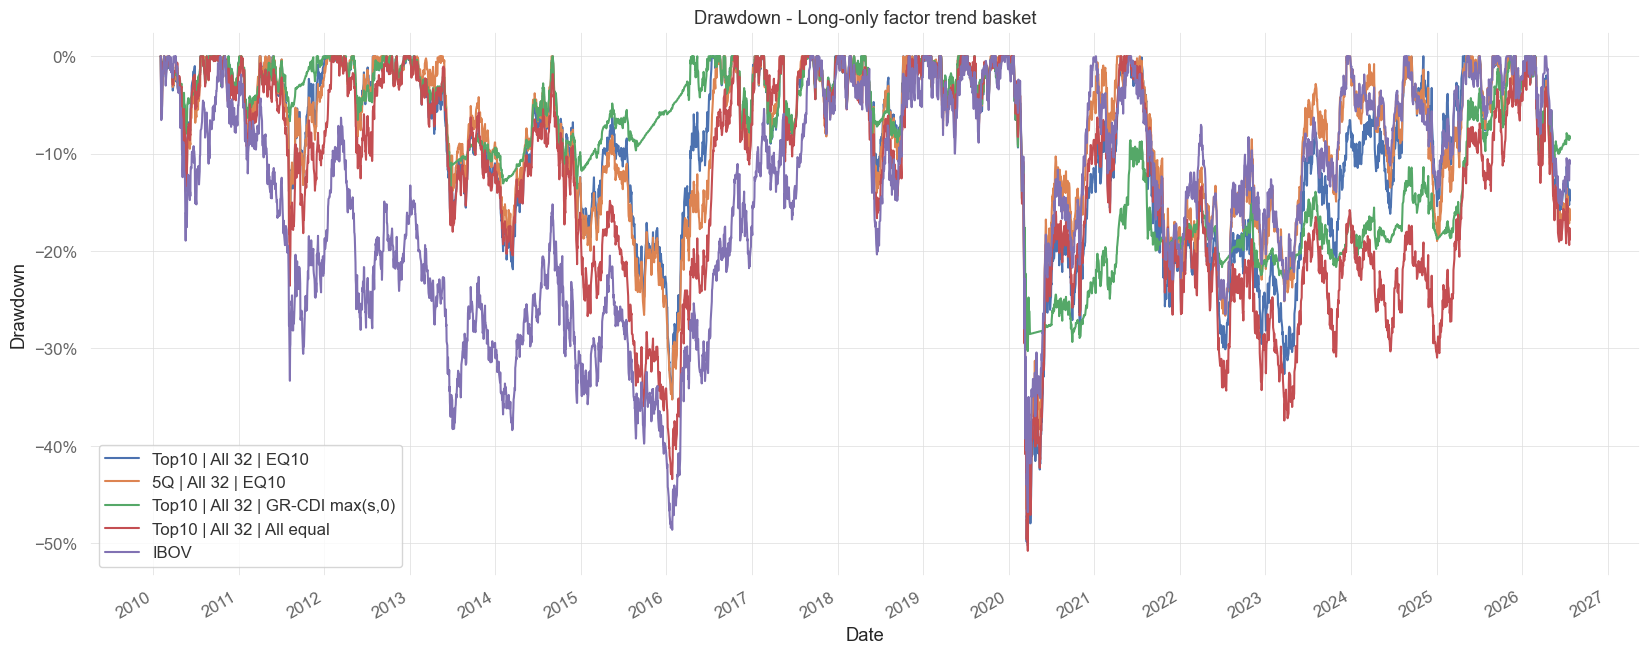

In [19]:
# Drawdowns of the main variants
for variant in main_variants:
    qs.stats.to_drawdown_series(stage2_returns[variant].dropna()).plot(figsize = (20,8), label = ' | '.join(variant))
qs.stats.to_drawdown_series(controls['IBOV']).plot(label = 'IBOV')

plt.title('Drawdown - Long-only factor trend basket')
plt.legend()
plt.ylabel('Drawdown')
plt.xlabel('Date')
plt.gca().yaxis.set_major_formatter(ticker.PercentFormatter(1.0, decimals = 0))
plt.gca().xaxis.set_major_locator(mdates.YearLocator(1))
plt.grid(True)

# Concentration

The measures below use the target weights of the stocks on each rebalance, leaving the CDI out:
- **Stocks**: the number of different stocks in the basket;
- **Max weight**: the largest stock weight, on average and at its peak;
- **Effective N**: `1 / sum(w^2)`, the number of equally weighted stocks that would give the same concentration;
- **Top 10 share**: the weight of the 10 largest positions;
- **Turnover**: half the sum of the absolute differences between the new weights, CDI included, and the weights of the month before after their drift, per rebalance.

In [20]:
# Prices used to drift the weights between two rebalances
prices_drift = prices_cdi.ffill()

concentration = dict()
for variant in variants:
    W = basket_weights[variant].copy()
    W.index = trade_dates
    W = W.loc[first_rebalance:]
    stocks = W.drop(columns = 'CDI')
    stocks = stocks.div(stocks.sum(axis = 1), axis = 0).fillna(0)

    turnover = []
    for dt0, dt1 in zip(W.index[:-1], W.index[1:]):
        drifted = (W.loc[dt0] * prices_drift.loc[dt1] / prices_drift.loc[dt0]).fillna(0)
        turnover.append(0.5 * (W.loc[dt1] - drifted / drifted.sum()).abs().sum())

    concentration[' | '.join(variant)] = {'Stocks': (stocks > 0).sum(axis = 1).mean(),
                                          'Max weight': stocks.max(axis = 1).mean(),
                                          'Max weight (peak)': stocks.max(axis = 1).max(),
                                          'Effective N': (1 / (stocks ** 2).sum(axis = 1)).replace(np.inf, np.nan).mean(),
                                          'Top 10 share': stocks.apply(lambda x: x.nlargest(10).sum(), axis = 1).mean(),
                                          'Turnover': np.mean(turnover)}

concentration = pd.DataFrame(concentration).T
concentration_fmt = concentration.copy()
for col in ['Max weight', 'Max weight (peak)', 'Top 10 share', 'Turnover']:
    concentration_fmt[col] = concentration_fmt[col].map('{:.1%}'.format)
for col in ['Stocks', 'Effective N']:
    concentration_fmt[col] = concentration_fmt[col].map('{:.0f}'.format)
concentration_fmt

,Stocks,Max weight,Max weight (peak),Effective N,Top 10 share,Turnover
Top10 | All 32 | EQ10,59,5.0%,8.0%,45,34.5%,32.4%
Top10 | All 32 | EQ10+,52,5.4%,10.0%,41,38.6%,37.5%
Top10 | All 32 | GR,80,4.9%,10.0%,51,36.2%,30.6%
Top10 | All 32 | GR-CDI (s+1)/2,59,5.1%,8.2%,44,35.3%,32.4%
"Top10 | All 32 | GR-CDI max(s,0)",52,5.7%,10.0%,39,41.2%,33.2%
Top10 | All 32 | All equal,107,3.3%,6.2%,74,23.8%,17.6%
Top10 | No composites | EQ10,62,4.6%,8.0%,48,31.9%,30.8%
Top10 | No composites | EQ10+,54,5.1%,10.0%,44,36.7%,36.3%
Top10 | No composites | GR,78,4.8%,10.0%,52,36.1%,31.3%
Top10 | No composites | GR-CDI (s+1)/2,62,4.7%,8.1%,47,33.1%,30.7%


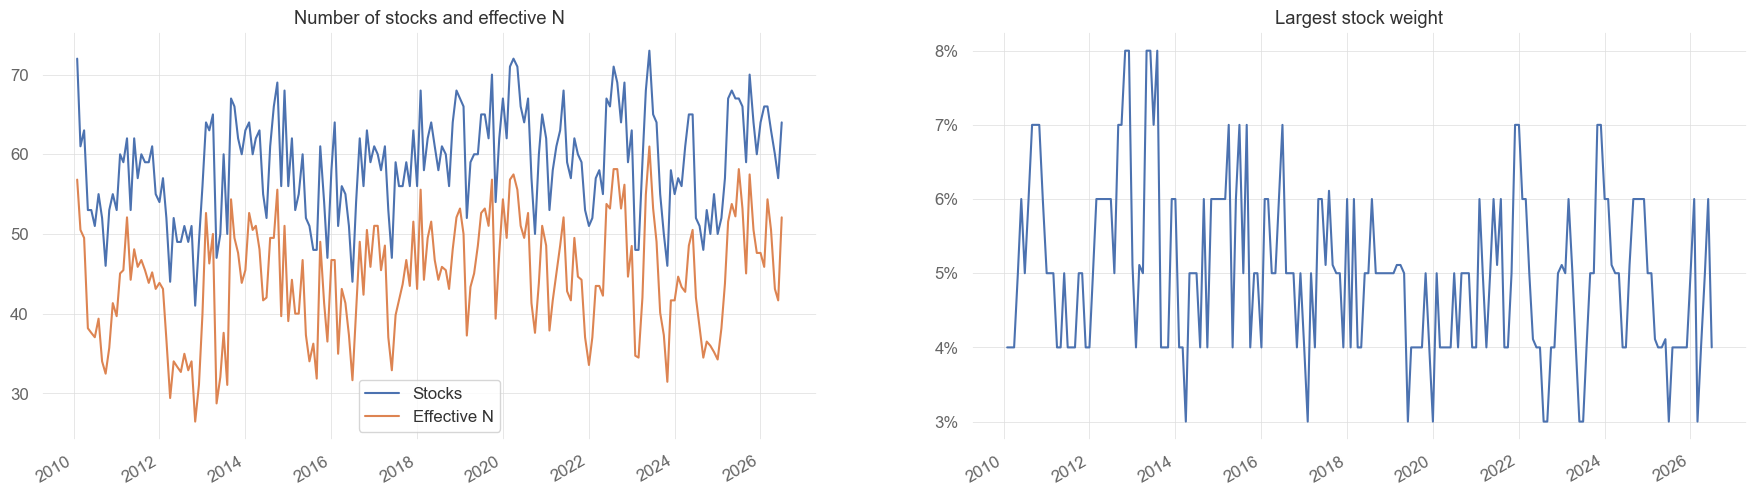

In [21]:
# Concentration over time, Top10 legs, all 32 factors, EQ10
W = basket_weights[('Top10', 'All 32', 'EQ10')].copy()
W.index = trade_dates
stocks = W.loc[first_rebalance:].drop(columns = 'CDI')

fig, axes = plt.subplots(1, 2, figsize = (22, 6))
pd.DataFrame({'Stocks': (stocks > 0).sum(axis = 1), 'Effective N': 1 / (stocks ** 2).sum(axis = 1)}).plot(ax = axes[0], title = 'Number of stocks and effective N')
stocks.max(axis = 1).plot(ax = axes[1], title = 'Largest stock weight')
axes[1].yaxis.set_major_formatter(ticker.PercentFormatter(1.0, decimals = 0))
for ax in axes:
    ax.grid(True)

In [22]:
# Average number of factors chosen from each family on each rebalance, EQ10
family_count = dict()
for leg in leg_types:
    for fset in factor_sets:
        chosen = factor_weights[(leg, fset, 'EQ10')].loc[first_rebalance:] > 0
        family_count[f'{leg} | {fset}'] = chosen.T.groupby(family_of).sum().T.mean()

pd.DataFrame(family_count).round(2)

,Top10 | All 32,Top10 | No composites,5Q | All 32,5Q | No composites
Growth,1.52,1.28,1.36,1.28
Leverage,1.27,1.42,1.30,1.23
Magic Formula,1.36,1.20,1.46,1.33
Market,1.98,2.29,2.22,2.56
Profitability,2.18,2.06,1.97,1.91
Value,1.69,1.74,1.68,1.70


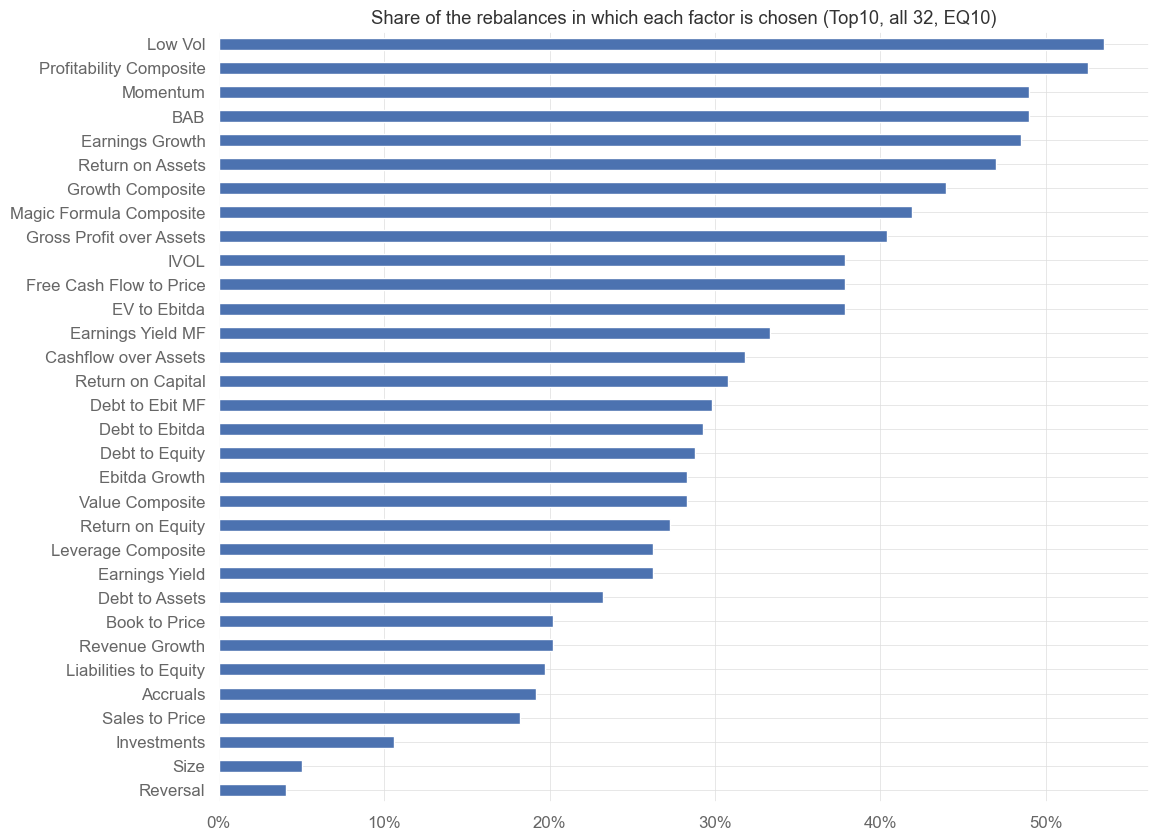

In [23]:
# How often each factor is chosen, Top10 legs, all 32 factors, EQ10
chosen = factor_weights[('Top10', 'All 32', 'EQ10')].loc[first_rebalance:] > 0
chosen.mean().sort_values().plot(kind = 'barh', figsize = (12, 10), title = 'Share of the rebalances in which each factor is chosen (Top10, all 32, EQ10)')
plt.gca().xaxis.set_major_formatter(ticker.PercentFormatter(1.0, decimals = 0))
plt.grid(True)

In [24]:
# Weight of each sector in the stock part of the basket, using the sector of the last index composition on or before the rebalance
sectors = companies.reset_index()[['Date', 'Ticker', 'Sector']].drop_duplicates()
sectors['Date'] = pd.to_datetime(sectors['Date'])

sector_weights = dict()
for variant in [('Top10', 'All 32', 'EQ10'), ('5Q', 'All 32', 'EQ10')]:
    W = basket_weights[variant].copy()
    W.index = trade_dates
    W = W.loc[first_rebalance:].drop(columns = 'CDI')

    by_date = []
    for dt, w in W.iterrows():
        w = w[w > 0]
        sector_of = sectors[sectors['Date'] <= dt].sort_values('Date').groupby('Ticker')['Sector'].last()
        by_date.append(w.groupby(sector_of.reindex(w.index).fillna('Unknown')).sum() / w.sum())
    by_date = pd.DataFrame(by_date).fillna(0)
    sector_weights[(' | '.join(variant), 'Mean')] = by_date.mean()
    sector_weights[(' | '.join(variant), 'Max')] = by_date.max()

pd.DataFrame(sector_weights).fillna(0).sort_values(('Top10 | All 32 | EQ10', 'Mean'), ascending = False).map('{:.1%}'.format)

Top10 | All 32 | EQ10         \
                                                 Mean    Max   
Sector                                                         
Consumo Cíclico                                 22.6%  40.0%   
Financeiro                                      12.6%  26.0%   
Utilidade Pública                               12.5%  29.0%   
Bens Industriais                                11.7%  28.3%   
Materiais Básicos                               10.8%  39.0%   
Consumo não Cíclico                              8.7%  23.0%   
Saúde                                            6.5%  18.0%   
Petróleo, Gás e Biocombustíveis                  5.5%  16.0%   
Tecnologia da Informação                         3.4%  14.0%   
Comunicações                                     2.8%  11.0%   
Consumo Não Cíclico                              1.4%  11.0%   
Financeiro e Outros                              0.8%   6.0%   
Construção e Transporte                          0.3%   7.0%   
Telecomunicações                                 0.3%   6.0%   
Outros                                           0.2%   3.0%   
Unknown                                          0.0%   1.0%   
Consumo não Cíclico                              0.0%   1.0%   
Hoteis e Restaurantes                            0.0%   0.0%   

                                5Q | All 32 | EQ10         
                                              Mean    Max  
Sector                                                     
Consumo Cíclico                              22.2%  40.3%  
Financeiro                                   12.5%  26.6%  
Utilidade Pública                            13.4%  28.6%  
Bens Industriais                             12.2%  20.7%  
Materiais Básicos                             9.9%  29.1%  
Consumo não Cíclico                           9.5%  20.2%  
Saúde                                         6.5%  16.7%  
Petróleo, Gás e Biocombustíveis               4.3%   9.5%  
Tecnologia da Informação                      3.2%  12.1%  
Comunicações                                  3.1%   9.0%  
Consumo Não Cíclico                           1.6%  10.3%  
Financeiro e Outros                           0.8%   4.1%  
Construção e Transporte                       0.2%   5.0%  
Telecomunicações                              0.3%   5.0%  
Outros                                        0.2%   3.2%  
Unknown                                       0.0%   0.6%  
Consumo não Cíclico                           0.0%   0.5%  
Hoteis e Restaurantes                         0.0%   0.5%

# Why the basket looks like the Combination

The cumulative return of EQ10 has a shape close to that of the Combination. The cells below separate what the two portfolios share. The reference is the equal-weighted investable universe: all the stocks of the SMLL and MLCX that pass the price and liquidity filters, rebalanced every month.

In [25]:
# Equal-weighted investable universe
universe = (investable * has_price * volume_filter).reindex(index = prices_df.index, columns = prices_df.columns).fillna(0)
ret_universe = backtest_quintiles(prices_df, universe, rebalance_dates, market_value)

compare = pd.DataFrame({'EQ10': stage2_returns[('Top10', 'All 32', 'EQ10')],
                        'All equal': stage2_returns[('Top10', 'All 32', 'All equal')],
                        'Combination': ret_comb,
                        'EW universe': ret_universe,
                        'IBOV': benchmarks['IBOV']}).loc[start_date:].dropna()
compare_monthly = compare.resample('ME').apply(lambda x: (x + 1).prod() - 1)

print('Correlation of the monthly returns')
compare_monthly.corr().round(2)

Correlation of the monthly returns


,EQ10,All equal,Combination,EW universe,IBOV
EQ10,1.00,0.97,0.92,0.96,0.88
All equal,0.97,1.00,0.91,0.99,0.91
Combination,0.92,0.91,1.00,0.91,0.83
EW universe,0.96,0.99,0.91,1.00,0.92
IBOV,0.88,0.91,0.83,0.92,1.00


In [26]:
# Returns over the equal-weighted universe
active = compare_monthly[['EQ10', 'All equal', 'Combination']].sub(compare_monthly['EW universe'], axis = 0)

r2_universe = {col: sm.OLS(compare_monthly[col], sm.add_constant(compare_monthly['EW universe'])).fit().rsquared for col in ['EQ10', 'All equal', 'Combination']}
print(pd.DataFrame({'Mean over the universe (year)': active.mean().mul(12).map('{:.1%}'.format),
                    'Tracking error': active.std().mul(np.sqrt(12)).map('{:.1%}'.format),
                    'R2 on the universe': pd.Series(r2_universe).map('{:.2f}'.format)}))
print('\nCorrelation of the returns over the universe')
active.corr().round(2)

            Mean over the universe (year) Tracking error R2 on the universe
EQ10                                 6.3%           5.9%               0.93
All equal                            2.0%           3.3%               0.98
Combination                          7.8%           9.4%               0.82

Correlation of the returns over the universe


,EQ10,All equal,Combination
EQ10,1.00,0.51,0.49
All equal,0.51,1.00,0.32
Combination,0.49,0.32,1.00


In [27]:
# Holdings overlap with the Combination on each rebalance: sum over the stocks of the smaller of the two weights
comb_holdings = long_mf + long_momvol + long_quality

overlap = dict()
for variant in [('Top10', 'All 32', 'EQ10'), ('Top10', 'All 32', 'All equal')]:
    values = []
    for dtm1 in signal_dates[trade_dates.index(first_rebalance):]:
        w = basket_weights[variant].loc[dtm1].drop('CDI')
        w = w[w > 0] / w[w > 0].sum()
        c = comb_holdings.loc[dtm1]
        c = c[c > 0] / c[c > 0].sum()
        if len(w) > 0 and len(c) > 0:
            values.append(np.minimum(w, c.reindex(w.index).fillna(0)).sum())
    overlap[' | '.join(variant)] = np.mean(values)

pd.Series(overlap).map('{:.1%}'.format)

Top10 | All 32 | EQ10         32.3%
Top10 | All 32 | All equal    28.2%
dtype: object

The two portfolios move together mostly because they buy from the same universe: EQ10 has an R² of about 0.93 on the equal-weighted universe, and the Combination is as correlated with the universe as it is with EQ10. What is left after the universe is moderately correlated, because the trend chooses most often the factors that make up the Combination: Low Vol, Profitability, Momentum and the Magic Formula. The stocks themselves overlap little: about a third of the weight, close to the overlap of the control with no trend.

# Robustness

Two checks of the factor choice, on the Stage 1 returns:
- **Signal lag**: the signal is taken some trading days before the usual date. A look-ahead error would make the result fall at once with one day of lag; a real trend signal fades slowly.
- **Random choice**: 10 factors drawn at random among the eligible ones on each rebalance, 500 times. EQ10 is compared with the distribution of the draws.

In [28]:
def top_factors(cols, n, lag = 0, leg = 'Top10'):
    # Equal weights on the n factors with the highest trend, using the signal 'lag' trading days before the usual date
    W = dict()
    for dt, dtm1 in zip(trade_dates, signal_dates):
        position = prices_df.index.get_loc(dtm1) - lag
        W[dt] = allocate(signals[leg].iloc[position][cols], 'EQ10', n)
    return pd.DataFrame(W).T.reindex(columns = cols).fillna(0)

def factor_series_return(W, cols, leg = 'Top10'):
    # Stage 1 return of a set of factor weights
    Wd = W.reindex(prices_df.index).ffill().shift(1)
    return ((Wd * leg_returns[leg][cols].fillna(0)).sum(axis = 1) + (1 - Wd.sum(axis = 1)) * cdi).loc[start_date:]

cols = factor_sets['All 32']
lag_test = {f'{lag} days': statistics(factor_series_return(top_factors(cols, 10, lag), cols)) for lag in [0, 1, 5, 21, 63]}
lag_test = pd.DataFrame(lag_test).T[['Annualized Return', 'Sharpe Ratio']]
lag_test['Annualized Return'] = lag_test['Annualized Return'].map('{:.1%}'.format)
lag_test['Sharpe Ratio'] = lag_test['Sharpe Ratio'].map('{:.2f}'.format)
lag_test

,Annualized Return,Sharpe Ratio
0 days,13.5%,0.26
1 days,14.1%,0.29
5 days,13.4%,0.26
21 days,11.2%,0.16
63 days,10.0%,0.11


  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 2/500 [00:00<00:25, 19.57it/s]

  1%|          | 4/500 [00:00<00:25, 19.42it/s]

  1%|          | 6/500 [00:00<00:25, 19.46it/s]

  2%|▏         | 8/500 [00:00<00:25, 19.40it/s]

  2%|▏         | 10/500 [00:00<00:25, 19.04it/s]

... (235 outputs left out)

 99%|█████████▉| 497/500 [00:26<00:00, 19.27it/s]

100%|██████████| 500/500 [00:26<00:00, 19.50it/s]

100%|██████████| 500/500 [00:26<00:00, 18.95it/s]

Random draws: mean 8.5%, 5th percentile 6.8%, 95th percentile 10.2%, maximum 11.9%
EQ10: 13.5%, above 100% of the draws


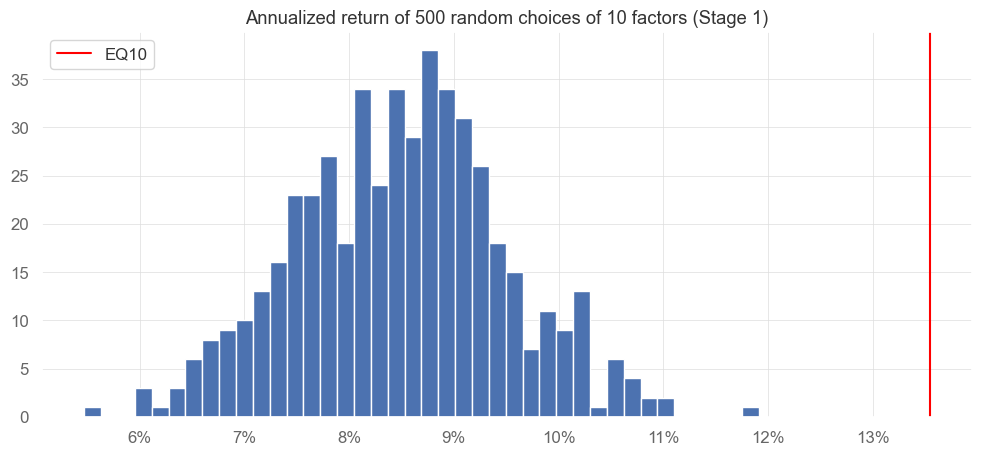

In [29]:
rng = np.random.default_rng(42)
eligible_factors = {dt: signals['Top10'].loc[dtm1, cols].dropna().index for dt, dtm1 in zip(trade_dates, signal_dates)}

random_returns = []
for draw in tqdm(range(500)):
    W = dict()
    for dt in trade_dates:
        w = pd.Series(0.0, index = cols)
        if len(eligible_factors[dt]) > 0:
            k = min(10, len(eligible_factors[dt]))
            w[rng.choice(eligible_factors[dt], k, replace = False)] = 1 / k
        W[dt] = w
    random_returns.append(statistics(factor_series_return(pd.DataFrame(W).T, cols))['Annualized Return'])
random_returns = np.array(random_returns)

eq10_return = statistics(factor_series_return(top_factors(cols, 10), cols))['Annualized Return']
print(f'Random draws: mean {random_returns.mean():.1%}, 5th percentile {np.percentile(random_returns, 5):.1%}, 95th percentile {np.percentile(random_returns, 95):.1%}, maximum {random_returns.max():.1%}')
print(f'EQ10: {eq10_return:.1%}, above {np.mean(random_returns < eq10_return):.0%} of the draws')

plt.figure(figsize = (12, 5))
plt.hist(random_returns, bins = 40)
plt.axvline(eq10_return, color = 'red', label = 'EQ10')
plt.title('Annualized return of 500 random choices of 10 factors (Stage 1)')
plt.gca().xaxis.set_major_formatter(ticker.PercentFormatter(1.0, decimals = 0))
plt.legend()
plt.grid(True)

# Composites and market factors only

The version without the composites keeps their components. This version does the opposite: it keeps only the five composites and the six market factors, which have no composite, so each theme enters once. With 11 factors, choosing 10 would hold almost all of them, so the test chooses the 3 to 6 factors with the best trend, with Top10 legs and equal weights, in the single basket of Stage 2.

The number of factors was chosen after looking at the results, so the whole table should be read together, not only its best line.

In [30]:
composite_set = composites + list(market.keys())

composite_results, composite_weights = dict(), dict()
for n in [3, 4, 5, 6, len(composite_set)]:
    name = f'Top {n} of {len(composite_set)}' if n < len(composite_set) else f'All {n} equal (control)'
    factor_weights[('Top10', name, 'EQ10')] = top_factors(composite_set, n)
    composite_weights[name] = stock_weights('Top10', name, 'EQ10')
    ret = backtest_quintiles(prices_cdi, composite_weights[name], rebalance_dates, market_value).loc[start_date:]

    stocks = composite_weights[name].loc[first_signal_date:].drop(columns = 'CDI')
    row = statistics(ret)
    row.update(nefin_regression(ret))
    row.update({'Stocks': (stocks > 0).sum(axis = 1).mean(), 'Max weight': stocks.max(axis = 1).mean(), 'Effective N': (1 / (stocks ** 2).sum(axis = 1)).mean()})
    composite_results[name] = row

composite_results = pd.DataFrame(composite_results).T
composite_fmt = composite_results.copy()
for col in ['Annualized Return', 'Volatility', 'Max Drawdown', 'Max weight']:
    composite_fmt[col] = composite_fmt[col].map('{:.1%}'.format)
composite_fmt['Alpha (month)'] = composite_fmt['Alpha (month)'].map('{:.2%}'.format)
for col in ['Sharpe Ratio', 'Alpha t-stat', 'Market beta']:
    composite_fmt[col] = composite_fmt[col].map('{:.2f}'.format)
for col in ['Stocks', 'Effective N']:
    composite_fmt[col] = composite_fmt[col].map('{:.0f}'.format)
composite_fmt

,Annualized Return,Volatility,Sharpe Ratio,Max Drawdown,Alpha (month),Alpha t-stat,Market beta,Stocks,Max weight,Effective N
Top 3 of 11,16.8%,18.5%,0.42,-40.6%,0.51%,2.75,0.83,25,7.5%,23
Top 4 of 11,15.5%,18.6%,0.36,-41.2%,0.48%,3.23,0.87,32,6.4%,28
Top 5 of 11,13.8%,19.2%,0.28,-45.9%,0.37%,2.54,0.90,38,5.8%,33
Top 6 of 11,13.3%,19.4%,0.25,-48.8%,0.38%,2.66,0.93,44,5.4%,37
All 11 equal (control),7.9%,20.6%,0.02,-48.9%,0.11%,0.83,0.98,71,3.9%,56


In [31]:
# How often each factor is chosen, top 5 of the 11
(factor_weights[('Top10', 'Top 5 of 11', 'EQ10')].loc[first_rebalance:] > 0).mean().sort_values(ascending = False).map('{:.0%}'.format)

Low Vol                    67%
Momentum                   60%
Profitability Composite    60%
Magic Formula Composite    58%
BAB                        56%
Growth Composite           53%
IVOL                       51%
Leverage Composite         40%
Value Composite            36%
Size                       13%
Reversal                    7%
dtype: object

# Conclusions

- Choosing the 10 factors with the best trend works better than holding all of them: with Top10 legs, EQ10 returns about 5 percentage points a year more than the control with the same factors and no trend, with a significant NEFIN alpha. It also beats all of 500 random choices of 10 factors, and its result fades slowly when the signal is lagged, as a real trend signal does.
- Using the trend to leave the stock market does not help. The long legs move mostly with the market, so their trend is mostly the market's trend, and the rules that send part of the money to the CDI miss the recoveries. They cut the drawdown and the market beta, but the alpha disappears.
- Weighting all factors by the strength of their trend (GR) spreads the money over about 20 factors and ends up like the control.
- Leaving out the composites barely changes the Top10 results. Keeping only the composites and the market factors, and choosing fewer of them, gives higher returns, but the number of factors was chosen in sample.
- The basket of EQ10 with Top10 legs holds about 60 stocks, with an effective N of about 45 and a largest weight of about 5%. Its turnover is high, about a third of the portfolio per month, so transaction costs would weigh more on it than on the control.
- The basket looks like the Combination of `05_` mostly because both buy from the same universe, and because the trend chooses most often the factors that make up the Combination. Over the same window, the Combination still does better than EQ10. Both are in sample: the factors of the Combination were chosen after the screening of `04_`, while EQ10 chooses them mechanically every month.